Loading hardware overlay...


Streaming structured commands...
Hardware execution complete!


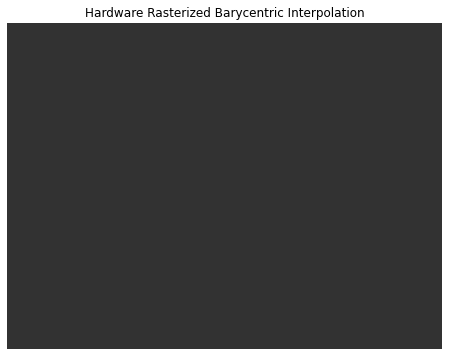

In [1]:
from pynq import Overlay, allocate
import numpy as np
import matplotlib.pyplot as plt

print("Loading hardware overlay...")
overlay = Overlay("softGPU.bit")
dma = overlay.axi_dma_0
gpu = overlay.soft_gpu_0

# 1. Allocate Memory matching exactly what C++ expects
# Hardware writes 32-bit integers at 320x240 resolution
frame_buffer = allocate(shape=(240, 320), dtype=np.int32)

# Fill background with a dark grey hex color (0x00323232)
frame_buffer[:] = 0x00323232
frame_buffer.flush()

cmd_type = np.dtype([('data', 'i4'), ('last', 'i4')])
cmd_buffer = allocate(shape=(9,), dtype=cmd_type)

# 2. Map the Memory Addresses
phys_addr = frame_buffer.physical_address
gpu.write(0x10, phys_addr & 0xFFFFFFFF)
gpu.write(0x14, (phys_addr >> 32) & 0xFFFFFFFF)

# Turn the GPU On!
gpu.write(0x00, 0x81)

# ==========================================
# 3. LOAD THE GEOMETRY & COLORS
# Hardware order: x, y, hex_color
# ==========================================
# Vertex 0: Top Middle (Red)
cmd_buffer[0]['data'] = 160; cmd_buffer[0]['last'] = 0 # x0
cmd_buffer[1]['data'] = 20;  cmd_buffer[1]['last'] = 0 # y0
cmd_buffer[2]['data'] = 0x00FF0000; cmd_buffer[2]['last'] = 0 # c0 (Red)

# Vertex 1: Bottom Right (Green)
cmd_buffer[3]['data'] = 280; cmd_buffer[3]['last'] = 0 # x1
cmd_buffer[4]['data'] = 220; cmd_buffer[4]['last'] = 0 # y1
cmd_buffer[5]['data'] = 0x0000FF00; cmd_buffer[5]['last'] = 0 # c1 (Green)

# Vertex 2: Bottom Left (Blue)
cmd_buffer[6]['data'] = 40;  cmd_buffer[6]['last'] = 0 # x2
cmd_buffer[7]['data'] = 220; cmd_buffer[7]['last'] = 0 # y2
# The last element MUST have the TLAST flag set to 1
cmd_buffer[8]['data'] = 0x000000FF; cmd_buffer[8]['last'] = 1 # c2 (Blue)

cmd_buffer.flush()

# 4. Execute
print("Streaming structured commands...")
dma.sendchannel.transfer(cmd_buffer)
dma.sendchannel.wait()
print("Hardware execution complete!")

# 5. Synchronize and Visualize
frame_buffer.sync_from_device()

# Unpack the 32-bit hardware hex colors into an RGB array for Matplotlib
rgb_image = np.zeros((240, 320, 3), dtype=np.uint8)
rgb_image[:, :, 0] = (frame_buffer >> 16) & 0xFF # Red Channel
rgb_image[:, :, 1] = (frame_buffer >> 8) & 0xFF  # Green Channel
rgb_image[:, :, 2] = frame_buffer & 0xFF         # Blue Channel

plt.figure(figsize=(8, 6))
plt.imshow(rgb_image)
plt.title("Hardware Rasterized Barycentric Interpolation")
plt.axis('off')
plt.show()

# Free memory when done
# frame_buffer.freebuffer()
# cmd_buffer.freebuffer()

In [3]:
from pynq import Overlay, allocate
import numpy as np
import matplotlib.pyplot as plt

print("Reloading hardware overlay...")
overlay = Overlay("softGPU.bit")
dma = overlay.axi_dma_0
gpu = overlay.soft_gpu_0

# 1. Allocate Memory (320x240, 32-bit int)
frame_buffer = allocate(shape=(240, 320), dtype=np.int32)

# Fill background with dark grey (Decimal: 3289650)
frame_buffer[:] = 0x00323232
frame_buffer.flush()

# Command Buffer
cmd_type = np.dtype([('data', 'i4'), ('last', 'i4')])
cmd_buffer = allocate(shape=(9,), dtype=cmd_type)

# 2. Map Memory using auto-resolving register names!
phys_addr = frame_buffer.physical_address
gpu.register_map.framebuffer_1 = phys_addr & 0xFFFFFFFF
gpu.register_map.framebuffer_2 = (phys_addr >> 32) & 0xFFFFFFFF

# Turn the GPU On (0x01 = Start once, no auto-restart)
gpu.write(0x00, 0x01)

# 3. Load Geometry (Red, Green, Blue triangle)
cmd_buffer[0]['data'] = 160; cmd_buffer[0]['last'] = 0 
cmd_buffer[1]['data'] = 20;  cmd_buffer[1]['last'] = 0 
cmd_buffer[2]['data'] = 0x00FF0000; cmd_buffer[2]['last'] = 0 

cmd_buffer[3]['data'] = 280; cmd_buffer[3]['last'] = 0 
cmd_buffer[4]['data'] = 220; cmd_buffer[4]['last'] = 0 
cmd_buffer[5]['data'] = 0x0000FF00; cmd_buffer[5]['last'] = 0 

cmd_buffer[6]['data'] = 40;  cmd_buffer[6]['last'] = 0 
cmd_buffer[7]['data'] = 220; cmd_buffer[7]['last'] = 0 
cmd_buffer[8]['data'] = 0x000000FF; cmd_buffer[8]['last'] = 1 
cmd_buffer.flush()

# 4. Execute DMA
print("Streaming commands...")
dma.sendchannel.transfer(cmd_buffer)
dma.sendchannel.wait()

# ==========================================
# 5. DIAGNOSTICS: LET'S LOOK AT THE SILICON
# ==========================================
# Read the Control Register to see if the GPU finished or hung
status = gpu.read(0x00)
print(f"GPU Hardware Status Register: {status} (4 or 14 = Done, 1 = Stuck/Hanging)")

# Sync RAM and check what the GPU actually wrote
frame_buffer.sync_from_device()
unique_colors = np.unique(frame_buffer)
print(f"Unique Colors in RAM (Hex): {[hex(c) for c in unique_colors]}")

Reloading hardware overlay...
Streaming commands...
GPU Hardware Status Register: 0 (4 or 14 = Done, 1 = Stuck/Hanging)
Unique Colors in RAM (Hex): ['0x323232']


Reloading hardware overlay...

Bypassing PYNQ to hit physical ignition registers...
 -> Jamming Start Bit into soft_gpu_0 at 0xa0020000

Streaming commands via DMA...
Unique Colors in RAM (Hex): ['0x323232']


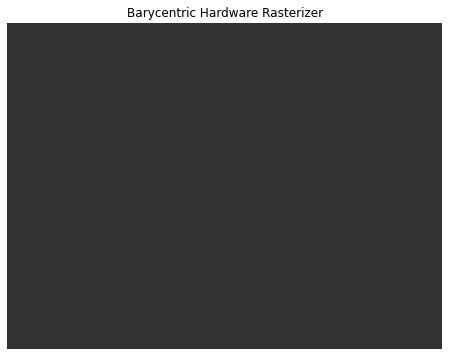

In [4]:
from pynq import Overlay, allocate, MMIO
import numpy as np
import matplotlib.pyplot as plt

print("Reloading hardware overlay...")
overlay = Overlay("softGPU.bit")
dma = overlay.axi_dma_0
gpu = overlay.soft_gpu_0

# 1. Allocate 320x240 memory
frame_buffer = allocate(shape=(240, 320), dtype=np.int32)
frame_buffer[:] = 0x00323232
frame_buffer.flush()

cmd_type = np.dtype([('data', 'i4'), ('last', 'i4')])
cmd_buffer = allocate(shape=(9,), dtype=cmd_type)

# 2. Map Pointers to Panel B (The one PYNQ knows about)
phys_addr = frame_buffer.physical_address
gpu.register_map.framebuffer_1 = phys_addr & 0xFFFFFFFF
gpu.register_map.framebuffer_2 = (phys_addr >> 32) & 0xFFFFFFFF

# ==========================================
# 3. THE SPLIT-BRAIN BYPASS
# Scan the processor for every piece of hardware belonging to the GPU
# and forcefully write 0x81 (Start + Auto-Restart) to offset 0x00!
# ==========================================
print("\nBypassing PYNQ to hit physical ignition registers...")
for name, info in overlay.ip_dict.items():
    if 'soft_gpu' in name:
        addr = info['phys_addr']
        print(f" -> Jamming Start Bit into {name} at {hex(addr)}")
        MMIO(addr, 0x1000).write(0x00, 0x81)

# 4. Load Geometry & Colors
cmd_buffer[0]['data'] = 160; cmd_buffer[0]['last'] = 0 
cmd_buffer[1]['data'] = 20;  cmd_buffer[1]['last'] = 0 
cmd_buffer[2]['data'] = 0x00FF0000; cmd_buffer[2]['last'] = 0 

cmd_buffer[3]['data'] = 280; cmd_buffer[3]['last'] = 0 
cmd_buffer[4]['data'] = 220; cmd_buffer[4]['last'] = 0 
cmd_buffer[5]['data'] = 0x0000FF00; cmd_buffer[5]['last'] = 0 

cmd_buffer[6]['data'] = 40;  cmd_buffer[6]['last'] = 0 
cmd_buffer[7]['data'] = 220; cmd_buffer[7]['last'] = 0 
cmd_buffer[8]['data'] = 0x000000FF; cmd_buffer[8]['last'] = 1 
cmd_buffer.flush()

# 5. Execute
print("\nStreaming commands via DMA...")
dma.sendchannel.transfer(cmd_buffer)
dma.sendchannel.wait()

# 6. Diagnostic Dump
frame_buffer.sync_from_device()
unique_colors = np.unique(frame_buffer)
print(f"Unique Colors in RAM (Hex): {[hex(c) for c in unique_colors]}")

# 7. Unpack and Visualize
rgb_image = np.zeros((240, 320, 3), dtype=np.uint8)
rgb_image[:, :, 0] = (frame_buffer >> 16) & 0xFF
rgb_image[:, :, 1] = (frame_buffer >> 8) & 0xFF
rgb_image[:, :, 2] = frame_buffer & 0xFF

plt.figure(figsize=(8, 6))
plt.imshow(rgb_image)
plt.title("Barycentric Hardware Rasterizer")
plt.axis('off')
plt.show()

Reloading hardware overlay...
Jamming ignition key directly into 0xA001_0000...
Streaming commands via DMA...


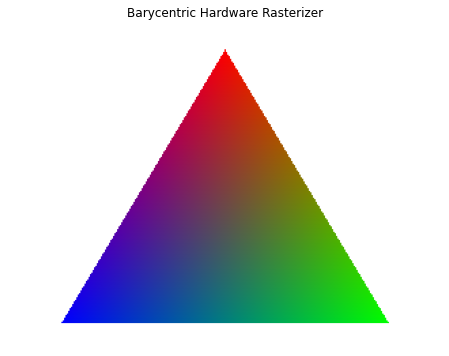

In [8]:
from pynq import Overlay, allocate, MMIO
import numpy as np
import matplotlib.pyplot as plt

print("Reloading hardware overlay...")
overlay = Overlay("softGPU.bit")
dma = overlay.axi_dma_0
gpu = overlay.soft_gpu_0

# 1. Allocate 320x240 memory
frame_buffer = allocate(shape=(240, 320), dtype=np.int32)
frame_buffer[:] = 0x00FFFFFF
frame_buffer.flush()

cmd_type = np.dtype([('data', 'i4'), ('last', 'i4')])
cmd_buffer = allocate(shape=(9,), dtype=cmd_type)

# 2. Map Pointers to Panel B (0xA002_0000) using PYNQ's known variable
phys_addr = frame_buffer.physical_address
gpu.register_map.framebuffer_1 = phys_addr & 0xFFFFFFFF
gpu.register_map.framebuffer_2 = (phys_addr >> 32) & 0xFFFFFFFF

# ==========================================
# 3. DIRECT IGNITION BYPASS
# Hardcoding the exact physical address from your Vivado screenshot!
# ==========================================
print("Jamming ignition key directly into 0xA001_0000...")
MMIO(0xA0010000, 0x1000).write(0x00, 0x81)

# 4. Load Geometry & Colors
cmd_buffer[0]['data'] = 160; cmd_buffer[0]['last'] = 0 
cmd_buffer[1]['data'] = 20;  cmd_buffer[1]['last'] = 0 
cmd_buffer[2]['data'] = 0x00FF0000; cmd_buffer[2]['last'] = 0 

cmd_buffer[3]['data'] = 280; cmd_buffer[3]['last'] = 0 
cmd_buffer[4]['data'] = 220; cmd_buffer[4]['last'] = 0 
cmd_buffer[5]['data'] = 0x0000FF00; cmd_buffer[5]['last'] = 0 

cmd_buffer[6]['data'] = 40;  cmd_buffer[6]['last'] = 0 
cmd_buffer[7]['data'] = 220; cmd_buffer[7]['last'] = 0 
cmd_buffer[8]['data'] = 0x000000FF; cmd_buffer[8]['last'] = 1 
cmd_buffer.flush()

# 5. Execute
print("Streaming commands via DMA...")
dma.sendchannel.transfer(cmd_buffer)
dma.sendchannel.wait()

# 6. Diagnostic Dump
frame_buffer.sync_from_device()
unique_colors = np.unique(frame_buffer)
#print(f"Unique Colors in RAM (Hex): {[hex(c) for c in unique_colors]}")

# 7. Unpack and Visualize
rgb_image = np.zeros((240, 320, 3), dtype=np.uint8)
rgb_image[:, :, 0] = (frame_buffer >> 16) & 0xFF
rgb_image[:, :, 1] = (frame_buffer >> 8) & 0xFF
rgb_image[:, :, 2] = frame_buffer & 0xFF

plt.figure(figsize=(8, 6))
plt.imshow(rgb_image)
plt.title("Barycentric Hardware Rasterizer")
plt.axis('off')
plt.show()

Initializing 3D Pipeline...
Streaming 12 triangles to the custom GPU...


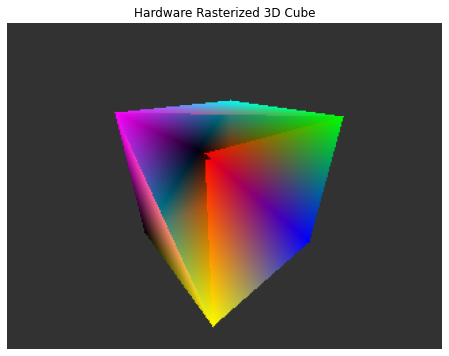

In [10]:
from pynq import Overlay, allocate, MMIO
import numpy as np
import matplotlib.pyplot as plt
import math

print("Initializing 3D Pipeline...")
overlay = Overlay("softGPU.bit")
dma = overlay.axi_dma_0
gpu = overlay.soft_gpu_0

# 1. Setup Memory (320x240 Canvas)
frame_buffer = allocate(shape=(240, 320), dtype=np.int32)
frame_buffer[:] = 0x00323232 # Clear the screen to dark grey
frame_buffer.flush()

# 12 Triangles * 9 elements per triangle = 108 commands
cmd_type = np.dtype([('data', 'i4'), ('last', 'i4')])
cmd_buffer = allocate(shape=(108,), dtype=cmd_type)

phys_addr = frame_buffer.physical_address
gpu.register_map.framebuffer_1 = phys_addr & 0xFFFFFFFF
gpu.register_map.framebuffer_2 = (phys_addr >> 32) & 0xFFFFFFFF
MMIO(0xA0010000, 0x1000).write(0x00, 0x81) # Auto-Restart Ignition

# ==========================================
# 2. THE 3D MATH (CPU VERTEX SHADER)
# ==========================================
# Define 8 vertices of a cube in 3D space (x, y, z)
vertices = np.array([
    [-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
    [-1, -1,  1], [1, -1,  1], [1, 1,  1], [-1, 1,  1]
])

# Assign a wild hex color to each vertex for hardware interpolation
colors = [0x00FF0000, 0x0000FF00, 0x000000FF, 0x00FFFF00, 
          0x00FF00FF, 0x0000FFFF, 0x00FFFFFF, 0x00000000]

# Define the 12 triangles that make up the 6 faces of the cube
faces = [
    (0,1,2), (0,2,3), # Front
    (5,4,7), (5,7,6), # Back
    (3,2,6), (3,6,7), # Top
    (4,5,1), (4,1,0), # Bottom
    (1,5,6), (1,6,2), # Right
    (4,0,3), (4,3,7)  # Left
]

# Rotation Angles (Spin it a bit to see the 3D effect)
angle_x, angle_y = 0.5, 0.7
cx, sx = math.cos(angle_x), math.sin(angle_x)
cy, sy = math.cos(angle_y), math.sin(angle_y)

projected_faces = []

for face in faces:
    pts_2d = []
    avg_z = 0
    
    for idx in face:
        x, y, z = vertices[idx]
        
        # Rotate Y axis
        x1 = x * cy - z * sy
        z1 = x * sy + z * cy
        # Rotate X axis
        y2 = y * cx - z1 * sx
        z2 = y * sx + z1 * cx
        
        # 3D to 2D Perspective Projection
        distance = 3.0 # Push the cube back from the camera
        z_w = z2 + distance
        
        # Scale to screen size (320x240)
        fov_scale = 150
        proj_x = int((x1 / z_w) * fov_scale + 160)
        proj_y = int((y2 / z_w) * fov_scale + 120)
        
        avg_z += z_w
        pts_2d.append((proj_x, proj_y, colors[idx]))
        
    # Store the 2D triangle along with its average depth for sorting
    projected_faces.append((avg_z / 3.0, pts_2d))

# PAINTER'S ALGORITHM: Sort triangles from furthest to closest!
# Since your hardware has no Z-buffer, we must draw the back of the cube first.
projected_faces.sort(key=lambda item: item[0], reverse=True)

# ==========================================
# 3. PACK THE HARDWARE STREAM
# ==========================================
cmd_idx = 0
for _, tri in projected_faces:
    for i in range(3):
        # Write X, Y, Color
        cmd_buffer[cmd_idx]['data'] = tri[i][0]; cmd_buffer[cmd_idx]['last'] = 0; cmd_idx += 1
        cmd_buffer[cmd_idx]['data'] = tri[i][1]; cmd_buffer[cmd_idx]['last'] = 0; cmd_idx += 1
        cmd_buffer[cmd_idx]['data'] = tri[i][2]; cmd_buffer[cmd_idx]['last'] = 0; cmd_idx += 1

# Tell the DMA the very last stream element is the end of the line
cmd_buffer[cmd_idx - 1]['last'] = 1
cmd_buffer.flush()

# ==========================================
# 4. EXECUTE HARDWARE
# ==========================================
print("Streaming 12 triangles to the custom GPU...")
dma.sendchannel.transfer(cmd_buffer)
dma.sendchannel.wait()

frame_buffer.sync_from_device()

# Unpack and Visualize
rgb_image = np.zeros((240, 320, 3), dtype=np.uint8)
rgb_image[:, :, 0] = (frame_buffer >> 16) & 0xFF
rgb_image[:, :, 1] = (frame_buffer >> 8) & 0xFF
rgb_image[:, :, 2] = frame_buffer & 0xFF

plt.figure(figsize=(8, 6))
plt.imshow(rgb_image)
plt.title("Hardware Rasterized 3D Cube")
plt.axis('off')
plt.show()

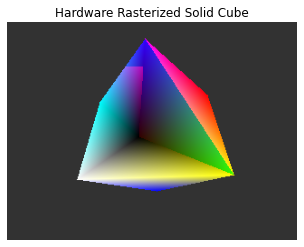

In [ ]:
from pynq import Overlay, allocate, MMIO
import numpy as np
import matplotlib.pyplot as plt
import math
import time
from IPython.display import display, clear_output

print("Initializing High-Speed 3D Pipeline...")
overlay = Overlay("softGPU.bit")
dma = overlay.axi_dma_0
gpu = overlay.soft_gpu_0

# 1. Setup Memory
frame_buffer = allocate(shape=(240, 320), dtype=np.int32)
cmd_type = np.dtype([('data', 'i4'), ('last', 'i4')])
cmd_buffer = allocate(shape=(108,), dtype=cmd_type)

phys_addr = frame_buffer.physical_address
gpu.register_map.framebuffer_1 = phys_addr & 0xFFFFFFFF
gpu.register_map.framebuffer_2 = (phys_addr >> 32) & 0xFFFFFFFF
MMIO(0xA0010000, 0x1000).write(0x00, 0x81) 

vertices = np.array([
    [-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
    [-1, -1,  1], [1, -1,  1], [1, 1,  1], [-1, 1,  1]
])
colors = [0x00FF0000, 0x0000FF00, 0x000000FF, 0x00FFFF00, 
          0x00FF00FF, 0x0000FFFF, 0x00FFFFFF, 0x00000000]
faces = [(0,1,2), (0,2,3), (5,4,7), (5,7,6), (3,2,6), (3,6,7), 
         (4,5,1), (4,1,0), (1,5,6), (1,6,2), (4,0,3), (4,3,7)]

# ==========================================
# OPTIMIZED MATPLOTLIB SETUP
# ==========================================
fig, ax = plt.subplots(figsize=(6, 4))
# Create a dummy image object once
rgb_image = np.zeros((240, 320, 3), dtype=np.uint8)
im = ax.imshow(rgb_image)
ax.set_title("Hardware Rasterized Solid Cube")
ax.axis('off')
display(fig)

# ==========================================
# HIGH-SPEED RENDER LOOP
# ==========================================
frames = 60
angle_x, angle_y = 0.0, 0.0

for frame in range(frames):
    frame_buffer[:] = 0x00323232 
    frame_buffer.flush()
    
    #anti ghosting
    cmd_buffer['data'] = 0
    cmd_buffer['last'] = 0
    
    angle_x += 0.1
    angle_y += 0.15
    cx, sx = math.cos(angle_x), math.sin(angle_x)
    cy, sy = math.cos(angle_y), math.sin(angle_y)

    projected_faces = []
    for face in faces:
        pts_2d = []
        avg_z = 0
        for idx in face:
            x, y, z = vertices[idx]
            x1, z1 = x * cy - z * sy, x * sy + z * cy
            y2, z2 = y * cx - z1 * sx, y * sx + z1 * cx
            
            z_w = z2 + 3.0
            fov_scale = 150
            proj_x = int((x1 / z_w) * fov_scale + 160)
            proj_y = int((y2 / z_w) * fov_scale + 120)
            
            avg_z += z_w
            pts_2d.append((proj_x, proj_y, colors[idx]))
            
        # --- BACKFACE CULLING FIX ---
        # Calculate the 2D cross product of the screen coordinates
        x0, y0 = pts_2d[0][0], pts_2d[0][1]
        x1, y1 = pts_2d[1][0], pts_2d[1][1]
        x2, y2 = pts_2d[2][0], pts_2d[2][1]
        
        cross_product = (x1 - x0) * (y2 - y0) - (y1 - y0) * (x2 - x0)
        
        # Only add the triangle if it is facing the camera!
        if cross_product > 0:
            projected_faces.append((avg_z / 3.0, pts_2d))

    projected_faces.sort(key=lambda item: item[0], reverse=True)

    # Pack the DMA Stream (Now only sending visible triangles!)
    cmd_idx = 0
    if len(projected_faces) > 0:
        for _, tri in projected_faces:
            for i in range(3):
                cmd_buffer[cmd_idx]['data'] = tri[i][0]; cmd_buffer[cmd_idx]['last'] = 0; cmd_idx += 1
                cmd_buffer[cmd_idx]['data'] = tri[i][1]; cmd_buffer[cmd_idx]['last'] = 0; cmd_idx += 1
                cmd_buffer[cmd_idx]['data'] = tri[i][2]; cmd_buffer[cmd_idx]['last'] = 0; cmd_idx += 1
        
        cmd_buffer[cmd_idx - 1]['last'] = 1 
        cmd_buffer.flush()

        # Fire Hardware
        dma.sendchannel.transfer(cmd_buffer)
        dma.sendchannel.wait()
        
    frame_buffer.sync_from_device()

    # Unpack and update the existing image data instead of redrawing the UI
    rgb_image[:, :, 0] = (frame_buffer >> 16) & 0xFF
    rgb_image[:, :, 1] = (frame_buffer >> 8) & 0xFF
    rgb_image[:, :, 2] = frame_buffer & 0xFF
    
    im.set_data(rgb_image)
    
    clear_output(wait=True)
    display(fig)

print("Animation Complete!")